# 07 — Sentiment Model Evaluation

Evaluates Llama 3.1 predictions (`llama_label`) against star-rating-derived ground truth (`sentiment_label`):

- **y_true**: `sentiment_label` — derived from star ratings (1-2 → negative, 3 → neutral, 4-5 → positive)
- **y_pred**: `llama_label` — Llama 3.1 predictions from review text

Metrics reported:
1. Accuracy
2. Weighted Precision
3. Weighted Recall
4. Weighted F1-score
5. Confusion Matrix

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

DATA_DIR = os.path.abspath("../data/processed/sentiment")
print("Libraries loaded.")

Libraries loaded.


## 1. Load Data

In [2]:
parts = glob.glob(os.path.join(DATA_DIR, "sentiment_scored", "part-*.parquet"))
df = pd.concat(
    [pd.read_parquet(p, columns=["sentiment_label", "llama_label", "llama_score", "source_category"]) for p in parts],
    ignore_index=True,
)

df["y_true"] = df["sentiment_label"].str.lower().str.strip()
df["y_pred"] = df["llama_label"].str.lower().str.strip()
df = df.dropna(subset=["y_true", "y_pred"])

CLASSES = ["positive", "neutral", "negative"]

print(f"Total samples : {len(df):,}")
print(f"\nGround truth distribution (y_true):")
print(df["y_true"].value_counts())
print(f"\nLlama 3.1 prediction distribution (y_pred):")
print(df["y_pred"].value_counts())

Total samples : 1,652

Ground truth distribution (y_true):
y_true
positive    1318
negative     253
neutral       81
Name: count, dtype: int64

Llama 3.1 prediction distribution (y_pred):
y_pred
positive    1188
negative     352
neutral      112
Name: count, dtype: int64


## 2. Metrics

In [3]:
y_true = df["y_true"]
y_pred = df["y_pred"]

accuracy  = accuracy_score(y_true, y_pred)
wt_prec   = precision_score(y_true, y_pred, average="weighted", zero_division=0)
wt_recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
wt_f1     = f1_score(y_true, y_pred, average="weighted", zero_division=0)

print("=" * 45)
print(f"  {'Metric':<25} {'Score':>8}")
print("=" * 45)
print(f"  {'Accuracy':<25} {accuracy:>8.4f}")
print(f"  {'Weighted Precision':<25} {wt_prec:>8.4f}")
print(f"  {'Weighted Recall':<25} {wt_recall:>8.4f}")
print(f"  {'Weighted F1-score':<25} {wt_f1:>8.4f}")
print("=" * 45)
print(f"\nPer-class report:")
print(classification_report(y_true, y_pred, labels=CLASSES, target_names=CLASSES, zero_division=0))

  Metric                       Score
  Accuracy                    0.8808
  Weighted Precision          0.9112
  Weighted Recall             0.8808
  Weighted F1-score           0.8901

Per-class report:
              precision    recall  f1-score   support

    positive       0.99      0.89      0.94      1318
     neutral       0.28      0.38      0.32        81
    negative       0.70      0.98      0.82       253

    accuracy                           0.88      1652
   macro avg       0.66      0.75      0.69      1652
weighted avg       0.91      0.88      0.89      1652



## 3. Confusion Matrix

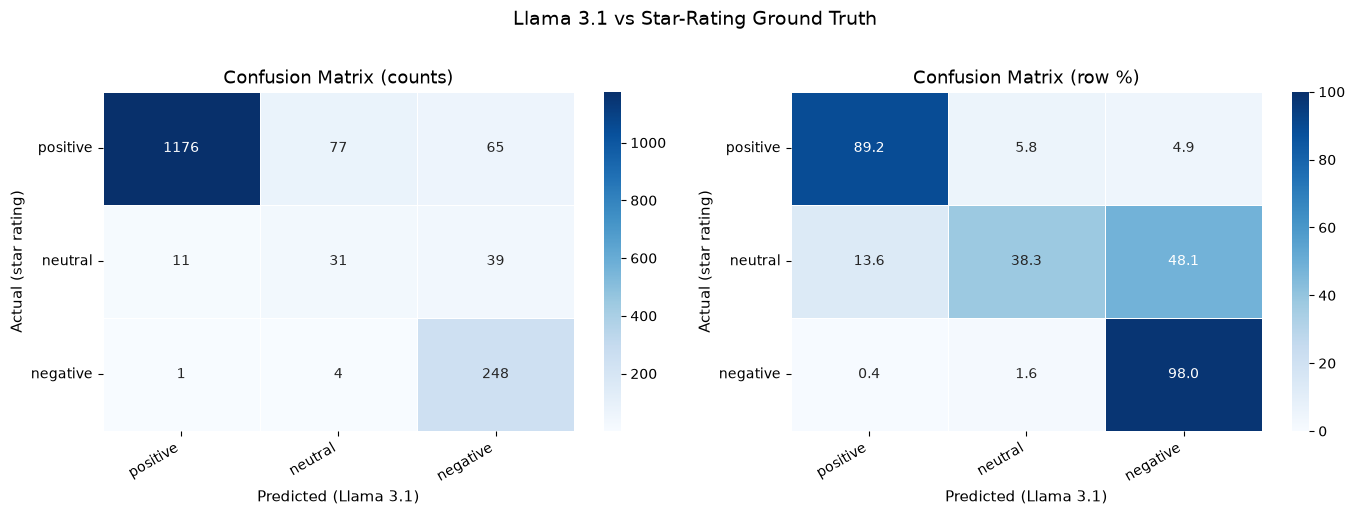

In [4]:
cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- raw counts ---
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASSES, yticklabels=CLASSES,
    ax=axes[0], linewidths=0.5,
)
axes[0].set_title("Confusion Matrix (counts)", fontsize=13)
axes[0].set_xlabel("Predicted (Llama 3.1)", fontsize=11)
axes[0].set_ylabel("Actual (star rating)", fontsize=11)

# --- row-normalised % ---
sns.heatmap(
    cm_pct, annot=True, fmt=".1f", cmap="Blues",
    xticklabels=CLASSES, yticklabels=CLASSES,
    ax=axes[1], linewidths=0.5,
    vmin=0, vmax=100,
)
axes[1].set_title("Confusion Matrix (row %)", fontsize=13)
axes[1].set_xlabel("Predicted (Llama 3.1)", fontsize=11)
axes[1].set_ylabel("Actual (star rating)", fontsize=11)

for ax in axes:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

plt.suptitle("Llama 3.1 vs Star-Rating Ground Truth", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 4. Weighted F1 by Category

 category  weighted_f1  accuracy   n
 Outdoors       0.9543    0.9416 154
   Mobile       0.9225    0.9140 500
  Apparel       0.9083    0.8945 256
Furniture       0.8938    0.8849 278
   Beauty       0.8888    0.8826 230
    Books       0.7495    0.7479 234


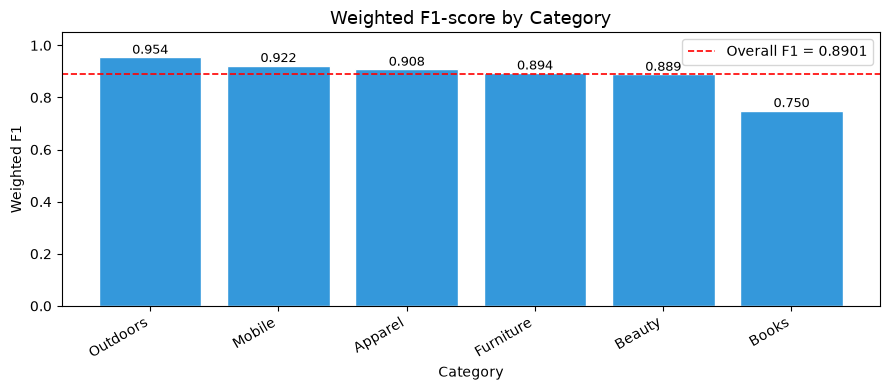

In [5]:
cat_metrics = []
for cat, grp in df.groupby("source_category"):
    f1 = f1_score(grp["y_true"], grp["y_pred"], average="weighted", zero_division=0)
    acc = accuracy_score(grp["y_true"], grp["y_pred"])
    cat_metrics.append({"category": cat, "weighted_f1": round(f1, 4), "accuracy": round(acc, 4), "n": len(grp)})

cat_df = pd.DataFrame(cat_metrics).sort_values("weighted_f1", ascending=False).reset_index(drop=True)
print(cat_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(cat_df["category"], cat_df["weighted_f1"], color="#3498db", edgecolor="white")
ax.axhline(wt_f1, color="red", linestyle="--", linewidth=1.2, label=f"Overall F1 = {wt_f1:.4f}")
for bar, val in zip(bars, cat_df["weighted_f1"]):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.002, f"{val:.3f}", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_title("Weighted F1-score by Category", fontsize=13)
ax.set_ylabel("Weighted F1")
ax.set_xlabel("Category")
ax.legend()
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 5. F1 by Sentiment Class × Category Heatmap

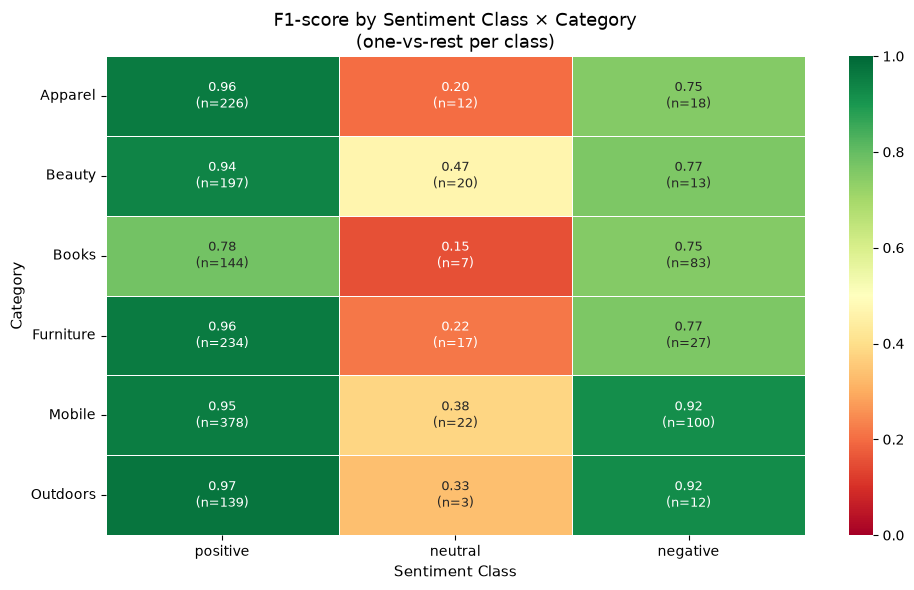


F1 pivot table:
sentiment  positive  neutral  negative
category                              
Apparel       0.959    0.200     0.750
Beauty        0.940    0.465     0.765
Books         0.778    0.154     0.750
Furniture     0.958    0.216     0.765
Mobile        0.955    0.379     0.920
Outdoors      0.970    0.333     0.923


In [6]:
heatmap_rows = []
for cat, grp in df.groupby("source_category"):
    for cls in CLASSES:
        # one-vs-rest F1 for this class within this category
        f1 = f1_score(
            grp["y_true"] == cls,
            grp["y_pred"] == cls,
            zero_division=0,
        )
        support = (grp["y_true"] == cls).sum()
        heatmap_rows.append({"category": cat, "sentiment": cls, "f1": round(f1, 3), "support": support})

heatmap_df = pd.DataFrame(heatmap_rows)
pivot = heatmap_df.pivot(index="category", columns="sentiment", values="f1")[CLASSES]
support_pivot = heatmap_df.pivot(index="category", columns="sentiment", values="support")[CLASSES]

# annotation: F1 + support count
annot = pivot.copy().astype(str)
for r in pivot.index:
    for c in pivot.columns:
        annot.loc[r, c] = f"{pivot.loc[r, c]:.2f}\n(n={support_pivot.loc[r, c]:,})"

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    pivot, annot=annot, fmt="", cmap="RdYlGn",
    vmin=0, vmax=1, linewidths=0.5, ax=ax,
    annot_kws={"size": 9},
)
ax.set_title("F1-score by Sentiment Class × Category\n(one-vs-rest per class)", fontsize=13)
ax.set_xlabel("Sentiment Class", fontsize=11)
ax.set_ylabel("Category", fontsize=11)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.tight_layout()
plt.show()

print("\nF1 pivot table:")
print(pivot.to_string())

## 6. Confidence Score Analysis

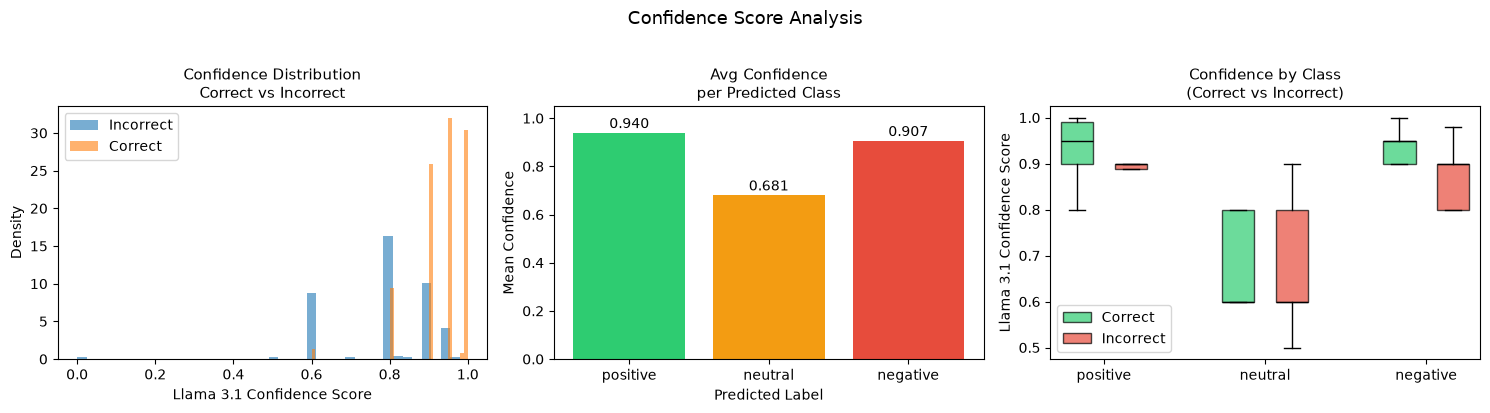


Summary:
             mean  median     std
Incorrect  0.7928    0.80  0.1314
Correct    0.9321    0.95  0.0690


In [7]:
df["correct"] = df["y_true"] == df["y_pred"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# --- Plot 1: confidence distribution correct vs incorrect ---
for label, grp in df.groupby("correct"):
    axes[0].hist(
        grp["llama_score"], bins=40, alpha=0.6,
        label="Correct" if label else "Incorrect", density=True,
    )
axes[0].set_title("Confidence Distribution\nCorrect vs Incorrect", fontsize=11)
axes[0].set_xlabel("Llama 3.1 Confidence Score")
axes[0].set_ylabel("Density")
axes[0].legend()

# --- Plot 2: avg confidence per predicted class ---
conf_by_class = df.groupby("y_pred")["llama_score"].mean().reindex(CLASSES)
axes[1].bar(conf_by_class.index, conf_by_class.values, color=["#2ecc71", "#f39c12", "#e74c3c"])
for i, (cls, val) in enumerate(conf_by_class.items()):
    axes[1].text(i, val + 0.005, f"{val:.3f}", ha="center", va="bottom", fontsize=10)
axes[1].set_title("Avg Confidence\nper Predicted Class", fontsize=11)
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Mean Confidence")
axes[1].set_ylim(0, 1.05)

# --- Plot 3: confidence boxplot correct vs incorrect per class ---
plot_data = [df[(df["y_pred"] == cls) & (df["correct"] == True)]["llama_score"].values for cls in CLASSES]
plot_data_wrong = [df[(df["y_pred"] == cls) & (df["correct"] == False)]["llama_score"].values for cls in CLASSES]
positions_correct = [1, 4, 7]
positions_wrong   = [2, 5, 8]
bp1 = axes[2].boxplot(plot_data, positions=positions_correct, widths=0.6,
                      patch_artist=True, boxprops=dict(facecolor="#2ecc71", alpha=0.7),
                      medianprops=dict(color="black"), showfliers=False)
bp2 = axes[2].boxplot(plot_data_wrong, positions=positions_wrong, widths=0.6,
                      patch_artist=True, boxprops=dict(facecolor="#e74c3c", alpha=0.7),
                      medianprops=dict(color="black"), showfliers=False)
axes[2].set_xticks([1.5, 4.5, 7.5])
axes[2].set_xticklabels(CLASSES)
axes[2].set_title("Confidence by Class\n(Correct vs Incorrect)", fontsize=11)
axes[2].set_ylabel("Llama 3.1 Confidence Score")
axes[2].legend([bp1["boxes"][0], bp2["boxes"][0]], ["Correct", "Incorrect"])

plt.suptitle("Confidence Score Analysis", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print("\nSummary:")
summary = df.groupby("correct")["llama_score"].agg(["mean","median","std"]).round(4)
summary.index = ["Incorrect", "Correct"]
print(summary.to_string())